In [95]:
import pandas as pd 

df = pd.read_csv("covid19.csv")
df = df.fillna(0)
df['Date_reported'] = pd.to_datetime(df['Date_reported'])
df

,Date_reported,Country_code,Country,Continent,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
0,2020-01-05,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
1,2020-01-12,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
2,2020-01-19,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
3,2020-01-26,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
4,2020-02-02,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
...,...,...,...,...,...,...,...,...,...
58555,2024-08-04,ZW,Zimbabwe,Africa,AFRO,1.0,266387,0.0,5740
58556,2024-08-11,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740
58557,2024-08-18,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740
58558,2024-08-25,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740


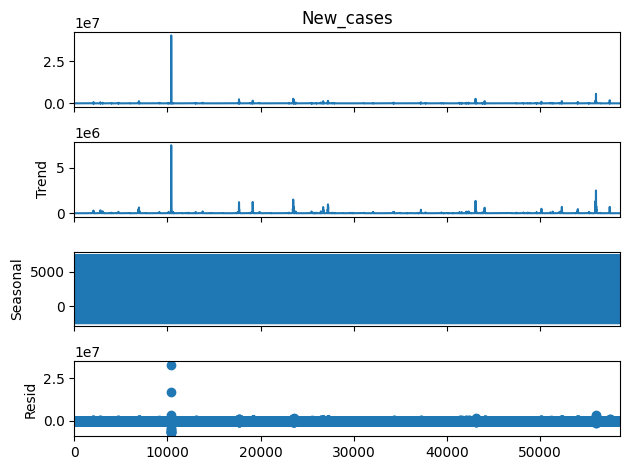

In [96]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

result = seasonal_decompose(df["New_cases"], model='additive', period=12)
result.plot()
plt.show()

In [97]:
musiman = pd.read_csv("/Applications/MAMP/htdocs/local/kodingakademi/Python/python 3/machine learning/statistics/time series/Contoh_Data_Musiman.csv")
musiman.head()

,Date,Value
0,2020-01-31,2.483571
1,2020-02-29,6.308678
2,2020-03-31,15.898697
3,2020-04-30,23.615149
4,2020-05-31,15.489487


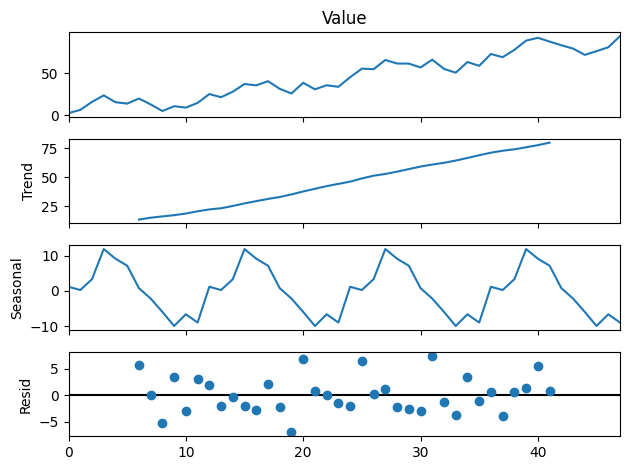

In [98]:
value = seasonal_decompose(musiman["Value"], model='additive', period=12)
value.plot()
plt.show()

MOVING AVERAGE

In [99]:
# Moving Average (7 hari)

df['Moving_Avg'] = df['New_deaths'].rolling(window=7).mean()
df[["New_deaths", "Moving_Avg"]].head(10)

,New_deaths,Moving_Avg
0,0.0,NaN
1,0.0,NaN
2,0.0,NaN
3,0.0,NaN
4,0.0,NaN
5,0.0,NaN
6,0.0,0.0
7,0.0,0.0
8,0.0,0.0
9,0.0,0.0


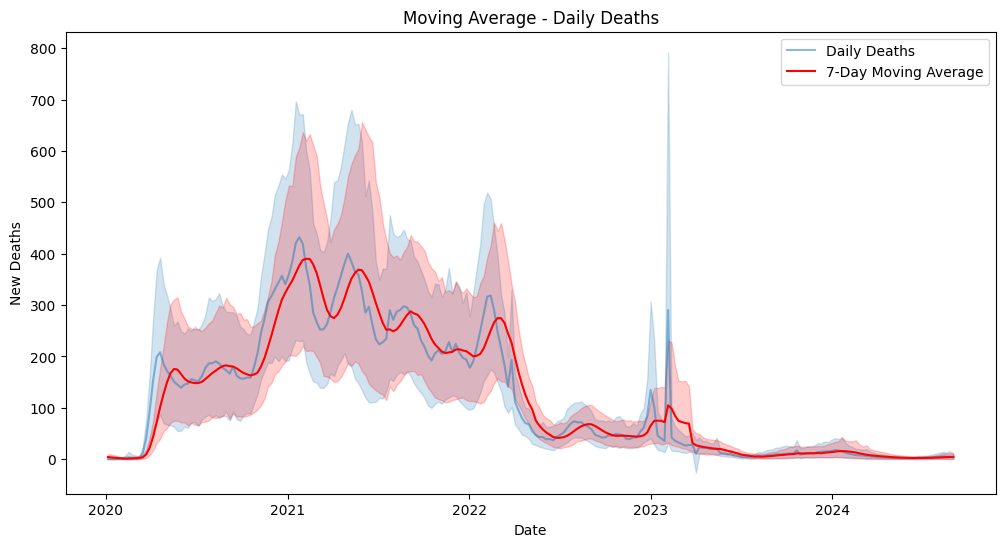

In [100]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.lineplot(x='Date_reported', y='New_deaths', data=df, label='Daily Deaths', alpha=0.5)
sns.lineplot(x='Date_reported', y='Moving_Avg', data=df, label='7-Day Moving Average', color='red')
plt.title('Moving Average - Daily Deaths')
plt.xlabel('Date')
plt.ylabel('New Deaths')
plt.legend()
plt.show()

EXPONENTIAL SMOOTHING

Single exponential smoothing

In [101]:
df

,Date_reported,Country_code,Country,Continent,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths,Moving_Avg
0,2020-01-05,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0,NaN
1,2020-01-12,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0,NaN
2,2020-01-19,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0,NaN
3,2020-01-26,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0,NaN
4,2020-02-02,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0,NaN
...,...,...,...,...,...,...,...,...,...,...
58555,2024-08-04,ZW,Zimbabwe,Africa,AFRO,1.0,266387,0.0,5740,0.0
58556,2024-08-11,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740,0.0
58557,2024-08-18,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740,0.0
58558,2024-08-25,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740,0.0


In [106]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

group = df.groupby("Date_reported")["New_deaths"].sum()

model = ExponentialSmoothing(group.values, trend="add", seasonal=None)
fit = model.fit()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


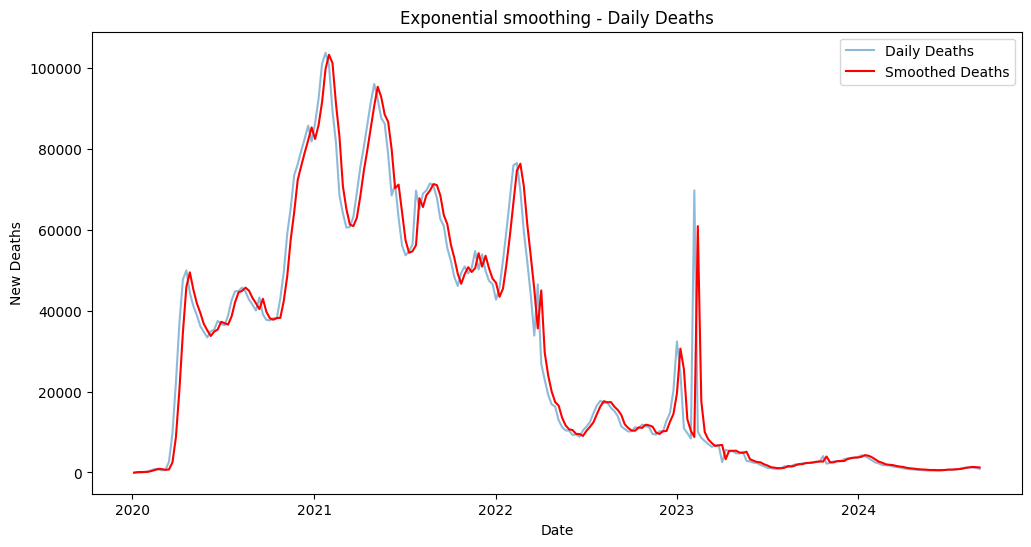

In [107]:
# Visualisasi

plt.figure(figsize=(12, 6))
sns.lineplot(x=group.index, y=group.values, label='Daily Deaths', alpha=0.5)
sns.lineplot(x=group.index, y=fit.fittedvalues, label='Smoothed Deaths', color='red')
plt.title('Exponential smoothing - Daily Deaths')
plt.xlabel('Date')
plt.ylabel('New Deaths')
plt.legend()
plt.show()

In [108]:
forecast = fit.forecast(steps=12)

print(forecast)

[1034.63434957 1126.69212829 1218.74990702 1310.80768574 1402.86546446
 1494.92324319 1586.98102191 1679.03880063 1771.09657936 1863.15435808
 1955.2121368  2047.26991553]
